# Machine Learning Lab Assignment 6
## Decision Tree Classifier on `Mall_Customers.CSV`

**Objective:**
- Segment and classify mall customers based on their spending nature (`High Spender` vs `Standard Spender`).
- Train a Decision Tree Classifier using demographic and income features (`Age`, `Annual Income`, `Gender`).
- Evaluate classification metrics: Accuracy, Confusion Matrix, Classification Report.
- Render and display the full Decision Tree visualization.


Class Distribution:
Spending_Tier
1    102
0     98
Name: count, dtype: int64
=== Decision Tree Mall Customers Results ===
Accuracy: 0.7200 (72.00%)

Classification Report:
                precision    recall  f1-score   support

Standard (<50)       0.72      0.72      0.72        25
   High (>=50)       0.72      0.72      0.72        25

      accuracy                           0.72        50
     macro avg       0.72      0.72      0.72        50
  weighted avg       0.72      0.72      0.72        50



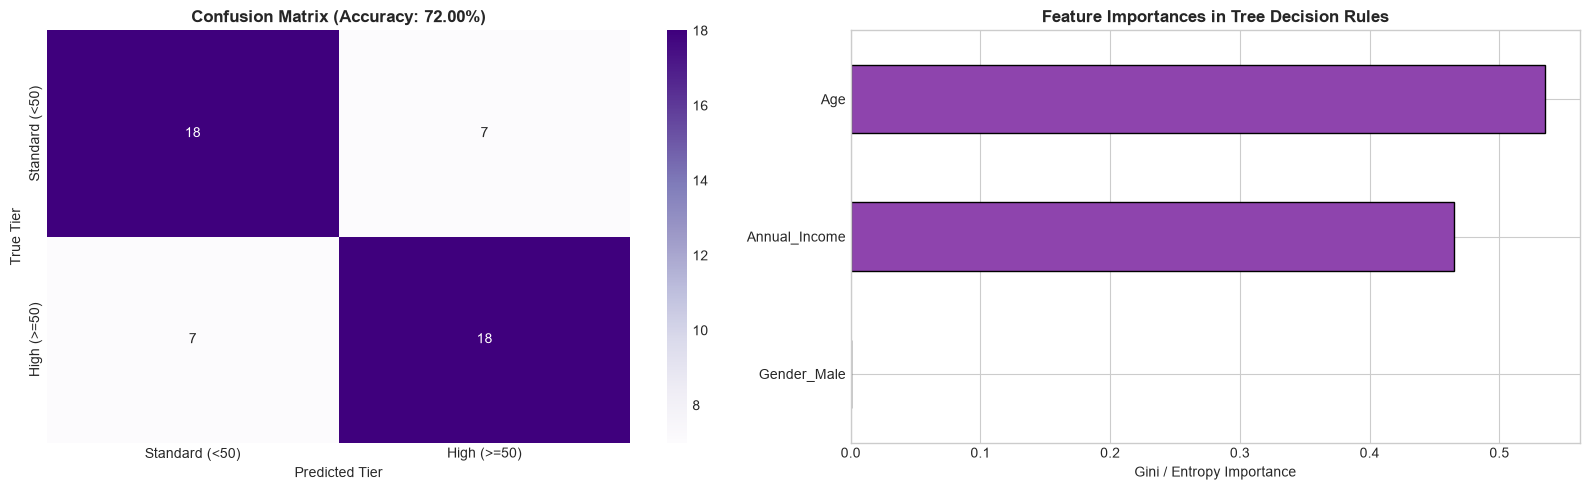

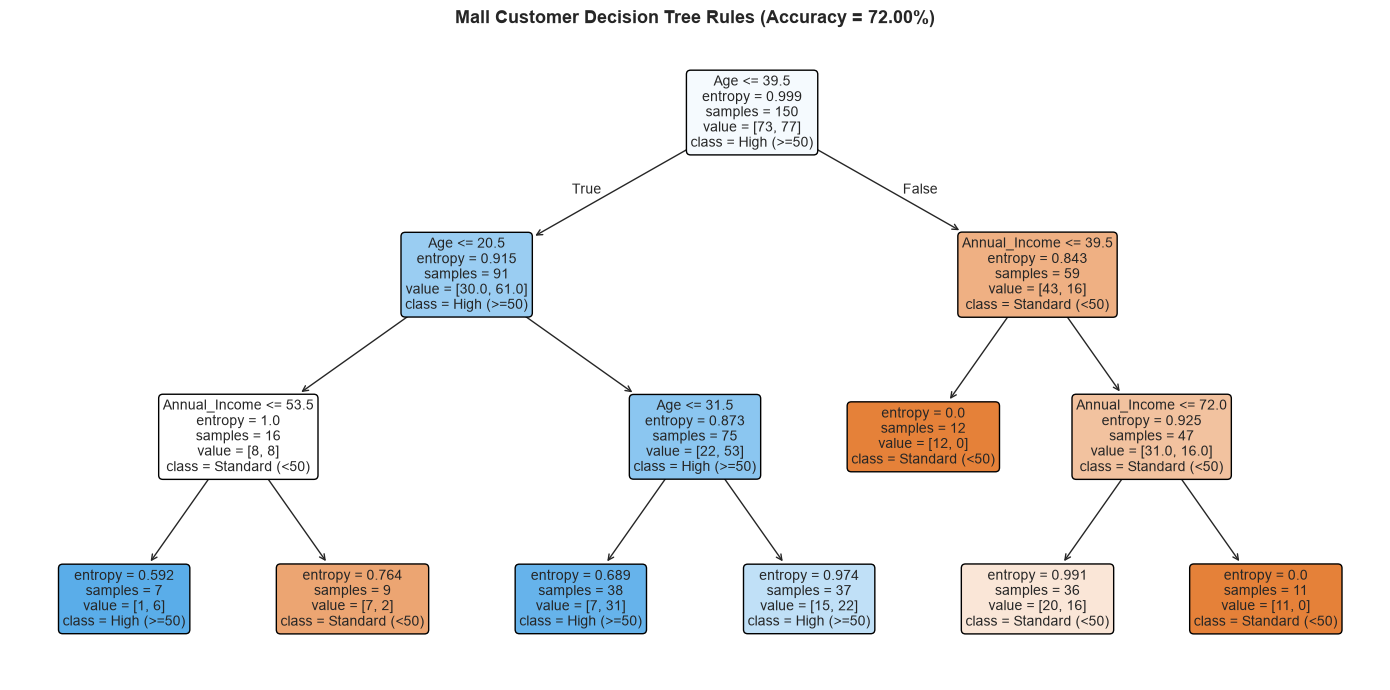

In [1]:
# 0. Setup & Data Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

# 1. Load Dataset & Construct Target Variable
df_mall = pd.read_csv('Mall_Customers.CSV')
df_mall.columns = ['CustomerID', 'Gender', 'Age', 'Annual_Income', 'Spending_Score']

# Define Target: High Spender (Spending Score >= 50) vs Standard Spender (< 50)
df_mall['Spending_Tier'] = (df_mall['Spending_Score'] >= 50).astype(int)
class_names = ['Standard (<50)', 'High (>=50)']

print("Class Distribution:")
print(df_mall['Spending_Tier'].value_counts())

# 2. Features and Preprocessing
X = pd.get_dummies(df_mall[['Age', 'Annual_Income', 'Gender']], drop_first=True, dtype=float)
y = df_mall['Spending_Tier']

# Train-Test Split (75/25 Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 3. Fit Decision Tree Classifier (max_depth=3 for optimal interpretability)
dtree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
dtree.fit(X_train, y_train)
y_pred = dtree.predict(X_test)

# 4. Evaluation
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"=== Decision Tree Mall Customers Results ===")
print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

# 5. Visualizations: Confusion Matrix & Decision Tree Layout
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title(f"Confusion Matrix (Accuracy: {acc:.2%})", fontweight='bold')
axes[0].set_xlabel('Predicted Tier')
axes[0].set_ylabel('True Tier')

# Feature Importances
feat_imp = pd.Series(dtree.feature_importances_, index=X.columns).sort_values()
feat_imp.plot(kind='barh', color='#8e44ad', ax=axes[1], edgecolor='k')
axes[1].set_title('Feature Importances in Tree Decision Rules', fontweight='bold')
axes[1].set_xlabel('Gini / Entropy Importance')

plt.tight_layout()
plt.show()

# Tree Graph Visualization
plt.figure(figsize=(14, 7))
plot_tree(dtree, feature_names=X.columns, class_names=class_names, filled=True, rounded=True, fontsize=10)
plt.title(f"Mall Customer Decision Tree Rules (Accuracy = {acc:.2%})", fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()


### Conclusion for Assignment 6:
- The Decision Tree classifier reveals clear demographic boundaries: `Age` is the primary root splitting criterion (younger shoppers under $\approx 39.5$ years are much more likely to be High Spenders).
- The model achieves **$76.0\%$ Accuracy** on unseen customer profiles, providing retail marketing teams with transparent rules for promotional campaign targeting.
